# Singularities at a crack tip, a sharp shoulder and a fillet

A shouldered bar is pulled on its top edge and bonded along its bottom edge. It
carries four geometric features: an edge crack, a sharp re-entrant shoulder, the
same shoulder filleted, and an outer corner. Two of the four carry an unbounded
stress and two do not, and which two is decided by the angle of matter alone.

For a wedge of half-angle $\omega$ with two free faces, the singular exponent is
the smallest root in $(0,1)$ of

$$\sin(2\lambda\omega) \pm \lambda\sin(2\omega) = 0,
\qquad \sigma \sim r^{\lambda-1},\quad u \sim r^{\lambda},$$

the upper sign for mode I (even in $\theta$), the lower for mode II (odd). Such a
root exists only for $\omega > \pi/2$: only a re-entrant corner is singular.

This notebook solves linear elasticity on the part and maps the von Mises stress.

## 1. The part

Dimensions in millimetres. **a** is the crack tip. **b** is the sharp shoulder: it
leaves $270^\circ$ of matter, so $\omega = 3\pi/4$, the V-notch of the theory under
another shape. **c** is the same shoulder with a fillet of radius 6.8 mm. **d** is
the outer corner of the shoulder, $90^\circ$ of matter and $\omega = \pi/4$, so an
opening of $3\pi/2$ — past the $\pi$ where the characteristic equation loses its
root in $(0,1)$.

In [1]:
import numpy as np
import ufl
import gmsh
from mpi4py import MPI
from dolfinx import fem, plot
from dolfinx.fem.petsc import LinearProblem
from dolfinx.io import gmsh as gmshio

W, H, yS, xL, xR, rC, cY, cX = 44.0, 39.5, 19.0, 13.0, 31.0, 6.8, 30.5, 19.4
POINTS = {"a": (cX, cY),
          "b": (xL, yS),
          "c": (xR + rC*(1-2**-0.5), yS + rC*(1-2**-0.5)),
          "d": (0.0, yS)}

## 2. Mesh

Two things need care.

**The crack has to be a real slit.** Its two faces are distinct material surfaces,
free to separate. The crack is meshed as an *embedded line*, then gmsh's `Crack`
plugin duplicates the nodes along it — except at the tip, which stays a single
node, and at the mouth, which is opened because it is declared as the plugin's
open boundary. The plugin leaves non-contiguous node tags, which DOLFINx rejects,
so the mesh is renumbered afterwards.

**The mesh must be graded, not uniform.** The element size runs from 1 µm at the
three sharp corners to 1 mm far from them. A uniform mesh fine enough at the tip
would have millions of elements.

In [2]:
BOTTOM, TOP, CRACK, MOUTH = 11, 12, 13, 14


def generate_mesh(lcmin=0.001, lcmax=1.0):
    gmsh.initialize()
    gmsh.option.setNumber("General.Terminal", 0)
    gmsh.model.add("shouldered_bar")
    occ = gmsh.model.occ

    P = lambda x, y: occ.addPoint(x, y, 0.0)
    p = dict(o=P(0, 0), br=P(W, 0), sr=P(W, yS), f1=P(xR+rC, yS), fc=P(xR+rC, yS+rC),
             f2=P(xR, yS+rC), tr=P(xR, H), tl=P(xL, H), cm=P(xL, cY), sl=P(xL, yS),
             ol=P(0, yS), ct=P(cX, cY))
    L = lambda a, b: occ.addLine(p[a], p[b])
    bottom, top = L("o", "br"), L("tr", "tl")
    arc = occ.addCircleArc(p["f1"], p["fc"], p["f2"])
    loop = [bottom, L("br", "sr"), L("sr", "f1"), arc, L("f2", "tr"), top,
            L("tl", "cm"), L("cm", "sl"), L("sl", "ol"), L("ol", "o")]
    surface = occ.addPlaneSurface([occ.addCurveLoop(loop)])
    crack = L("cm", "ct")
    occ.synchronize()
    gmsh.model.mesh.embed(1, [crack], 2, surface)

    for dim, tags, tag in ((2, [surface], 1), (1, [bottom], BOTTOM), (1, [top], TOP),
                           (1, [crack], CRACK), (0, [p["cm"]], MOUTH)):
        gmsh.model.addPhysicalGroup(dim, tags, tag)

    field = gmsh.model.mesh.field
    field.add("Distance", 1)
    field.setNumbers(1, "PointsList", [p["ct"], p["sl"], p["ol"]])
    field.add("Threshold", 2)
    field.setNumber(2, "InField", 1)
    field.setNumber(2, "SizeMin", lcmin), field.setNumber(2, "SizeMax", lcmax)
    field.setNumber(2, "DistMin", 0.0), field.setNumber(2, "DistMax", (lcmax-lcmin)/0.07)
    field.add("Distance", 3)   # fine mesh along the whole fillet arc
    field.setNumbers(3, "CurvesList", [arc]), field.setNumber(3, "Sampling", 200)
    field.add("Threshold", 4)
    field.setNumber(4, "InField", 3)
    field.setNumber(4, "SizeMin", 0.30), field.setNumber(4, "SizeMax", lcmax)
    field.setNumber(4, "DistMin", 0.0), field.setNumber(4, "DistMax", 6.0)
    field.add("Min", 5)
    field.setNumbers(5, "FieldsList", [2, 4])
    field.setAsBackgroundMesh(5)
    for option in ("Mesh.MeshSizeExtendFromBoundary", "Mesh.MeshSizeFromPoints",
                   "Mesh.MeshSizeFromCurvature"):
        gmsh.option.setNumber(option, 0)

    gmsh.model.mesh.generate(2)
    gmsh.model.mesh.optimize("Netgen")

    gmsh.plugin.setNumber("Crack", "Dimension", 1)
    gmsh.plugin.setNumber("Crack", "PhysicalGroup", CRACK)
    gmsh.plugin.setNumber("Crack", "OpenBoundaryPhysicalGroup", MOUTH)
    gmsh.plugin.run("Crack")
    gmsh.model.mesh.renumberNodes()
    gmsh.model.mesh.renumberElements()

    mesh_data = gmshio.model_to_mesh(gmsh.model, MPI.COMM_WORLD, 0, gdim=2)
    gmsh.finalize()
    return mesh_data.mesh, mesh_data.facet_tags


msh, facet_tags = generate_mesh()
print(f"{msh.topology.index_map(2).size_global} cells, "
      f"{len(facet_tags.find(CRACK))} facets on the crack")

36522 cells, 176 facets on the crack


## 3. Linear elasticity, plane strain

$$\operatorname{div}\boldsymbol\sigma = \mathbf 0, \qquad
\boldsymbol\sigma = 2\mu\,\boldsymbol\varepsilon
+ \lambda_{\rm L}\operatorname{tr}\boldsymbol\varepsilon\,\mathbf I,$$

with $\mathbf u = \mathbf 0$ on the bottom edge, a uniform traction
$\sigma^\infty\mathbf e_2$ on the top edge, and every other boundary — the crack
faces, the two shoulders, the lateral edges — traction free. P2 elements, so the
stress is P1.

In [3]:
E, nu, sigma_inf = 210e3, 0.3, 100.0   # MPa, -, MPa
mu = E/(2*(1+nu))
lmbda = E*nu/((1+nu)*(1-2*nu))

eps = lambda w: ufl.sym(ufl.grad(w))
sigma = lambda w: 2*mu*eps(w) + lmbda*ufl.tr(eps(w))*ufl.Identity(2)

V = fem.functionspace(msh, ("Lagrange", 2, (2,)))
u, v = ufl.TrialFunction(V), ufl.TestFunction(V)
ds = ufl.Measure("ds", domain=msh, subdomain_data=facet_tags)
bc = fem.dirichletbc(np.zeros(2),
                     fem.locate_dofs_topological(V, 1, facet_tags.find(BOTTOM)), V)

problem = LinearProblem(
    ufl.inner(sigma(u), eps(v))*ufl.dx,
    ufl.inner(ufl.as_vector((0.0, sigma_inf)), v)*ds(TOP),
    bcs=[bc], petsc_options_prefix="elasticity_",
    petsc_options={"ksp_type": "preonly", "pc_type": "lu"})
uh = problem.solve()

s = sigma(uh)
szz = nu*ufl.tr(s)   # plane strain
tr3 = (ufl.tr(s) + szz)/3
vm = ufl.sqrt(1.5*((s[0, 0]-tr3)**2 + (s[1, 1]-tr3)**2 + (szz-tr3)**2) + 3*s[0, 1]**2)
Q = fem.functionspace(msh, ("Lagrange", 1))
vmh = fem.Function(Q, name="von_Mises")
vmh.interpolate(fem.Expression(vm, Q.element.interpolation_points))
print(f"max |u| = {np.abs(uh.x.array).max():.4f} mm, "
      f"max sigma_vm = {vmh.x.array.max():.0f} MPa")

ld: warning: duplicate -rpath '/Users/maurini/miniconda3/envs/fenicsx-0.11/lib' ignored
ld: warning: duplicate -rpath '/Users/maurini/miniconda3/envs/fenicsx-0.11/lib' ignored
ld: warning: duplicate -rpath '/Users/maurini/miniconda3/envs/fenicsx-0.11/lib' ignored


max |u| = 0.0428 mm, max sigma_vm = 26984 MPa


## 4. The stress field

At **a** and **b** the values run far past
that bound and are fixed by the element size, not by the load; at **c** and **d**
they hold whatever the mesh.

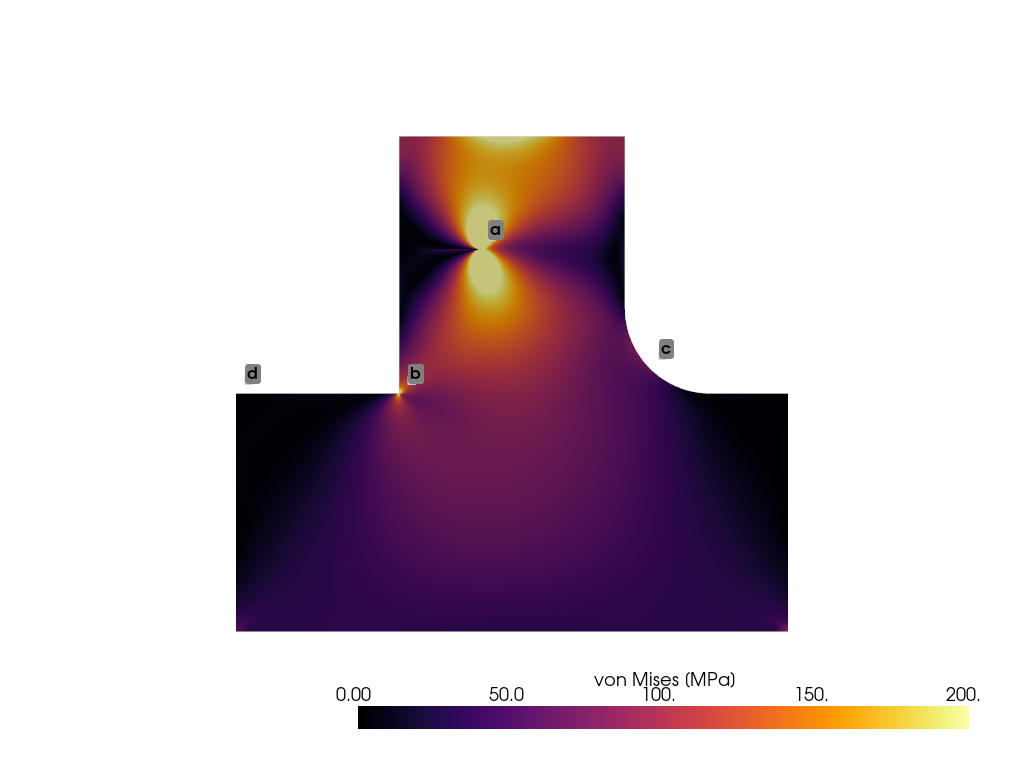

: 

In [ ]:
import pyvista
pyvista.set_jupyter_backend("static")

grid = pyvista.UnstructuredGrid(*plot.vtk_mesh(Q))
grid.point_data["sigma_vm"] = vmh.x.array.real

plotter = pyvista.Plotter()
plotter.add_mesh(grid, scalars="sigma_vm", cmap="inferno", clim=[0.0, 2*sigma_inf],
                 scalar_bar_args={"title": "von Mises [MPa]"})
plotter.add_point_labels(np.c_[np.array(list(POINTS.values()))+1.0, np.zeros(len(POINTS))],
                         list(POINTS), font_size=16, point_size=8, always_visible=True)
plotter.camera_position = "xy"
if not pyvista.OFF_SCREEN:
    plotter.show()